# Linear model: performance on the eval year

An analysis of the linear model (`models.linear_model`, `docs/linear_model.md`) on the held-out
eval year, 2025-10-20 → 2026-10-20: 1,448 forecast runs, one every 6 hours, each 72 hours long.
The model was selected and fitted on the training years only. The eval year was scored once by
`python -m training.linear_model evaluate`; this notebook breaks that score down. Nothing here
feeds back into the model's choices.

The model is a per-lead Gaussian GLM on the target **speed − last observed speed** (relative to
persistence, no Box-Cox transform), weighted by each run's TIMSE weights. Its inputs are the
final baseline's speed terms (last speed, 27-day and 13.5-day recurrence) plus four regressors:

| Regressor | What it is |
|---|---|
| `bt_mean_1h` | field strength Bt, mean of the last hour |
| `ch_cm_at_24h` | coronal-hole area in the central-meridian strip, AIA 193 image 24 h before t0 (falling back to the 30 h, then 36 h image) |
| `xray_peak_max_72h` | log peak X-ray flare flux in the last 72 h |
| `density_mean_24h` | proton density, mean of the last 24 h |

**This is the shipped model, re-selected and refitted on 9 years** (2016-10 → 2025-10, `docs/linear_model.md`, "Nine years of history"):
- **Selection:** the variant search and forward selection ran on six yearly walk-forward folds (2019-10 → 2025-10).
- **Data fixes:** despiking and the coronal-hole submodel are kept.
- **What changed:** it kept the same variant and kinds of signal. Bt (last hour) now comes first; the coronal-hole strip moved to 24 h, the flare flux to 72 h, and field variability dropped out.

Earlier versions of this notebook analysed the 4-year fits; their findings led to the data fixes.

It is compared against the **final baseline** (the reference model and current submission) and
**persistence**. The 4-year models' headline scores are quoted from `docs/linear_model.md` where useful.

1. **Scores:** overall, and how the per-run distribution changes.
2. **By regime:** the run labels of `final_baseline_analysis.ipynb` (CME, stream arrival, quiet wind…).
3. **Bias and level:** does the regression fix the baseline's over-forecast of quiet wind?
4. **Stream arrivals:** does the coronal-hole regressor give arrival timing?
5. **The regressors:** coefficients, contributions, ablation, and the coronal-hole archive gap.
6. **Through the year and the worst runs.**
7. **Findings.**

**Conventions:**
- **Residual** = actual − forecast; negative means the model over-predicted.
- **Ratio** = a run's TIMSE for one model divided by another's for the same run. Below 1, the first model wins.
- **Per-run** scores treat each 72-hour run on its own, as the platform scores each submission.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from feature_engineering.recurrence import last_observed, targets
from models.final_baseline import FinalBaseline, run_timse_weights
from models.linear_model import LinearModel
from training import solar_wind_events as ev
from training.datasets import EVAL_END, TRAIN_END, load_hourly
from training.evaluate import HORIZON, forecast_times, run_timse
from training.linear_model import candidate_table
from training.metrics import timse

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

MODELS = ["linear_model", "final_baseline", "persistence"]
STYLE = {
    "linear_model": {"color": "#eb6834", "lw": 1.8},
    "final_baseline": {"color": "#2a78d6", "lw": 1.5},
    "persistence": {"color": "#8a8984", "lw": 1.5, "ls": (0, (1, 1.5))},
}
REGIME_COLORS = {
    "CME": "#e34948", "possible CME": "#e87ba4", "stream arrival": "#eda100",
    "fast stream": "#6250d6", "slow wind": "#1baf7a", "intermediate": "#52514e",
}
CME_SPAN = {"color": "#e34948", "alpha": 0.18, "lw": 0}
POSSIBLE_SPAN = {"color": "#e87ba4", "alpha": 0.18, "lw": 0}
GAP_SPAN = {"color": "#6250d6", "alpha": 0.12, "lw": 0}
WIN, LOSE = "#1baf7a", "#6250d6"
lead = np.arange(1, HORIZON + 1)


def model_legend(fig, extra=(), models=MODELS):
    handles = [Line2D([], [], **STYLE[m]) for m in models]
    labels = list(models)
    for handle, label in extra:
        handles.append(handle)
        labels.append(label)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0),
               ncol=len(handles), frameon=False, fontsize=9)


def fmt(table):
    return table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else x)

## 1. Scores

The linear model is loaded from the shipped asset (fitted on the training years) and run
walk-forward over every eval `t0`. Its regressors are built from the pulled history
(`training.pull_features`) with the live availability rules. As live, a run without a coronal-hole
image goes to the submodel and other missing regressors take their training medians. The batch
forecast is checked against the live `predict()` path on one run, and on one submodel run.

In [2]:
series = load_hourly()
values = series.to_numpy()
t0s = forecast_times()
pos = series.index.get_indexer(t0s)
actual = targets(values, pos)

model = LinearModel.load()
FEATURES = list(model.config.features)
table = candidate_table(t0s)
x = table[FEATURES].to_numpy(dtype=float)
imputed = pd.DataFrame(np.isnan(x), index=t0s, columns=FEATURES)

forecasts = {
    "linear_model": model.forecast(values, pos, x),
    "final_baseline": FinalBaseline.load().forecast(values, pos),
    "persistence": np.repeat(last_observed(values, pos)[:, None], HORIZON, 1),
}
submodel = pd.Series(model.uses_fallback(x), index=t0s)
for i in (700, int(np.flatnonzero(submodel)[10])):
    row = dict(zip(FEATURES, x[i], strict=True))
    assert np.allclose(model.predict(series.iloc[: pos[i]], row), forecasts["linear_model"][i])

residuals = {m: actual - f for m, f in forecasts.items()}
run_scores = pd.DataFrame({m: run_timse(forecasts[m], actual) for m in MODELS}, index=t0s)
vs_base = run_scores["linear_model"] / run_scores["final_baseline"]
vs_pers = run_scores["linear_model"] / run_scores["persistence"]
base_vs_pers = run_scores["final_baseline"] / run_scores["persistence"]

overall = pd.DataFrame({
    m: {
        "pooled TIMSE": timse(actual, forecasts[m]),
        "per-run mean": run_scores[m].mean(),
        "per-run median": run_scores[m].median(),
        "per-run p90": run_scores[m].quantile(0.9),
        "RMSE": float(np.sqrt(np.nanmean(residuals[m] ** 2))),
        "beats persistence": (run_scores[m] < run_scores["persistence"]).mean(),
    }
    for m in MODELS
}).T
print(f"{len(t0s)} runs; linear beats the final baseline in {(vs_base < 1).mean():.0%} of runs")
print("regressors missing (share of runs):", imputed.mean().round(3).to_dict())
print(f"runs forecast by the submodel (no coronal-hole image): {submodel.mean():.1%}")
fmt(overall)

1448 runs; linear beats the final baseline in 66% of runs
regressors missing (share of runs): {'bt_mean_1h': 0.014, 'ch_cm_at_24h': 0.194, 'xray_peak_max_72h': 0.0, 'density_mean_24h': 0.005}
runs forecast by the submodel (no coronal-hole image): 19.4%


,pooled TIMSE,per-run mean,per-run median,per-run p90,RMSE,beats persistence
linear_model,4.82e+07,2.34e+06,6.67e+05,3.43e+06,103,0.584
final_baseline,5.58e+07,2.59e+06,8.45e+05,3.21e+06,110,0.532
persistence,8.13e+07,5.57e+06,7.76e+05,1.38e+07,110,0


**The per-run distribution.** The per-run mean is what the platform's per-run scoring averages,
and it is set by the worst runs. The table compares the two models' per-run TIMSE at several
quantiles. The scatter puts every run's linear-model TIMSE against the final baseline's: below the
diagonal, the linear model wins.

,linear_model,final_baseline,linear / baseline
p10,1.95e+05,2.48e+05,0.784
p25,3.61e+05,4.39e+05,0.823
p50,6.67e+05,8.45e+05,0.79
p75,1.41e+06,1.64e+06,0.859
p90,3.43e+06,3.21e+06,1.07
p95,6.92e+06,7.99e+06,0.865
p99,3.61e+07,4.67e+07,0.772


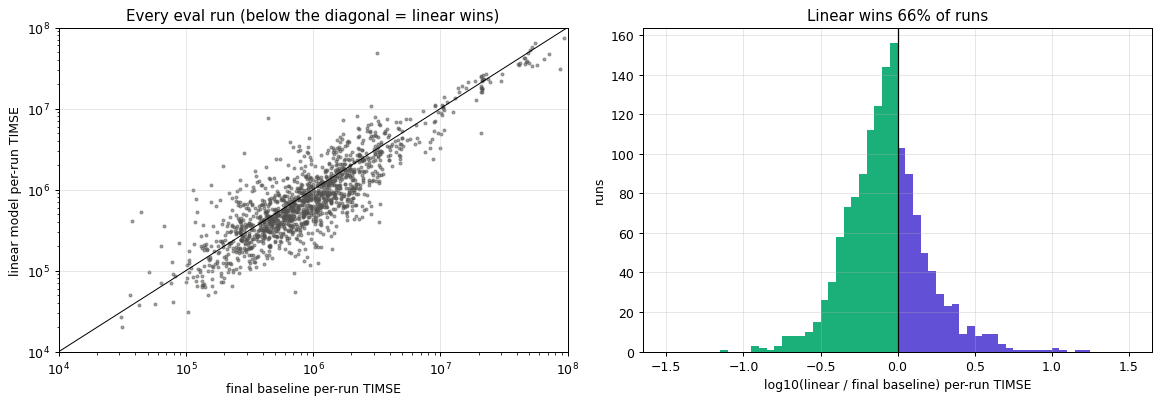

In [3]:
qs = [0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
quant = pd.DataFrame({m: run_scores[m].quantile(qs) for m in MODELS[:2]})
quant["linear / baseline"] = quant["linear_model"] / quant["final_baseline"]
quant.index = [f"p{int(q * 100)}" for q in qs]
display(fmt(quant))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
lo, hi = 1e4, 1e8
ax.plot([lo, hi], [lo, hi], color="k", lw=0.8)
ax.scatter(run_scores["final_baseline"], run_scores["linear_model"], s=5, alpha=0.5,
           color="#52514e")
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi),
       xlabel="final baseline per-run TIMSE", ylabel="linear model per-run TIMSE",
       title="Every eval run (below the diagonal = linear wins)")
ax = axes[1]
r = np.log10(vs_base.dropna())
bins = np.linspace(-1.5, 1.5, 61)
ax.hist(r[r < 0], bins=bins, color=WIN)
ax.hist(r[r >= 0], bins=bins, color=LOSE)
ax.axvline(0, color="k", lw=1)
ax.set(xlabel="log10(linear / final baseline) per-run TIMSE", ylabel="runs",
       title=f"Linear wins {(r < 0).mean():.0%} of runs")
fig.tight_layout()

**Forecasts along the year.** The observed speed against the forecasts, from the first eval
run and then one run every 3 days. Runs are 72 h long, so each forecast starts where the
previous one ends: the forecasts tile the year without overlapping. Dotted lines mark each
run's `t0`, where the forecast restarts from the latest observation. One row per quarter.

In the 4-year first fit, some runs here were spiky bands: the forecast jumped at every sixth lead
(32, 38, … 68 h) after large flares. That was the training-data glitch of section 5.5.

With despiking, the bands are gone, but a smaller hour-to-hour jitter remains in some runs. It
comes from training on 6-hourly runs (section 5.5).

121 non-overlapping runs, 2025-10-20 00Z to 2026-10-18 00Z
per-run mean TIMSE on these runs: {'linear_model': '1.87e+06', 'final_baseline': '2.17e+06', 'persistence': '4.4e+06'} | linear wins 67%


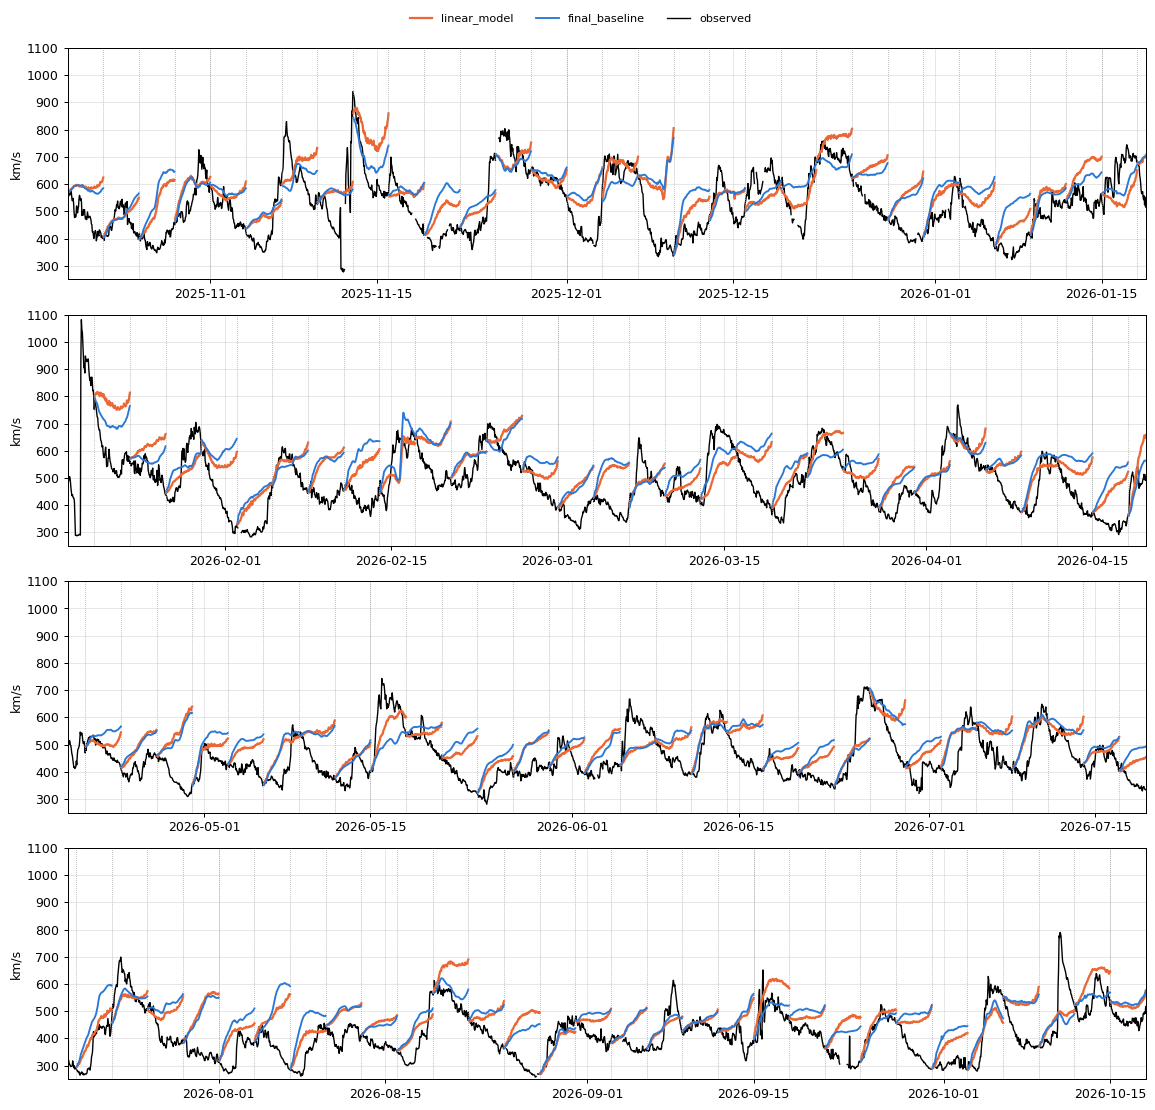

In [4]:
STRIDE = 72 // 6  # runs are 6-hourly; every 12th run is 3 days apart
tiled = np.arange(0, len(t0s), STRIDE)
tiled_times = [t0s[i] + pd.to_timedelta(lead, unit="h") for i in tiled]
valid_hours = tiled_times[0].append(tiled_times[1:])
# consecutive runs: no overlap and no gap
assert valid_hours.is_unique and (np.diff(valid_hours.asi8) == 3600 * 10**9).all()

tiled_scores = run_scores.iloc[tiled]
print(f"{len(tiled)} non-overlapping runs, {t0s[tiled[0]]:%Y-%m-%d %H}Z to "
      f"{t0s[tiled[-1]] + pd.Timedelta(hours=HORIZON):%Y-%m-%d %H}Z")
print("per-run mean TIMSE on these runs:",
      {m: f"{tiled_scores[m].mean():.3g}" for m in MODELS},
      f"| linear wins {(tiled_scores['linear_model'] < tiled_scores['final_baseline']).mean():.0%}")

quarters = pd.date_range(t0s[0], t0s[tiled[-1]] + pd.Timedelta(hours=HORIZON + 1), periods=5)
fig, axes = plt.subplots(4, 1, figsize=(13, 12))
for k, ax in enumerate(axes):
    lo, hi = quarters[k], quarters[k + 1]
    obs = series[lo:hi]
    ax.plot(obs.index, obs, color="k", lw=1.1)
    for r, i in enumerate(tiled):  # one line per run, so separate runs aren't joined
        if lo <= t0s[i] < hi:
            for m in MODELS[:2]:
                ax.plot(tiled_times[r], forecasts[m][i], **STYLE[m])
    for t in t0s[tiled][(t0s[tiled] >= lo) & (t0s[tiled] < hi)]:
        ax.axvline(t, color="0.6", lw=0.6, ls=":")
    ax.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.1), "observed")], models=MODELS[:2])

## 2. By regime

Each run is labelled by what happened during its 72 target hours (`ev.classify_runs`, as in
`final_baseline_analysis.ipynb`): CME, possible CME, stream arrival, fast stream, slow wind
(peak below 450 km/s), intermediate. The last four are the no-CME regimes.

For each regime:
- **runs** and their share of the year;
- **per-run mean** for both models, and the **change in the per-run total** it contributes (the regime's share of the overall change in the sum of per-run TIMSE: negative is a gain for the linear model);
- **median ratio** linear / baseline and how often the linear model wins;
- the median ratio of each model against persistence;
- **pooled TIMSE** of the linear model over the final baseline's, on the regime's runs.

In [5]:
cond_start = pd.Timestamp("2025-07-01T00:00Z")
minutes = ev.load_conditions(cond_start, EVAL_END)
hourly = minutes.resample("h").mean().reindex(
    pd.date_range(cond_start, EVAL_END, freq="h", inclusive="left", name="Time")
)
events = ev.detect_icmes(hourly, ev.detect_shocks(minutes))
cme = ev.cme_mask(hourly.index, events)
possible = ev.cme_mask(hourly.index, events, ("possible ICME",))
arrivals = ev.detect_stream_arrivals(hourly["speed"], cme | possible)
cme_hours = cme.reindex(series.index, fill_value=False)
possible_hours = possible.reindex(series.index, fill_value=False)
regime = pd.Series(ev.classify_runs(t0s, actual, cme_hours, arrivals, possible_hours),
                   index=t0s, name="regime")
no_cme = regime.isin(ev.NO_CME).to_numpy()

diff = run_scores["linear_model"] - run_scores["final_baseline"]
total_change = diff.sum()


def regime_row(sel):
    lin, base = run_scores.loc[sel, "linear_model"], run_scores.loc[sel, "final_baseline"]
    return {
        "runs": int(sel.sum()),
        "share of runs": sel.mean(),
        "linear mean": lin.mean(),
        "baseline mean": base.mean(),
        "share of total change": diff[sel].sum() / abs(total_change),
        "median linear / baseline": vs_base[sel].median(),
        "linear wins": (vs_base[sel] < 1).mean(),
        "median linear / persistence": vs_pers[sel].median(),
        "median baseline / persistence": base_vs_pers[sel].median(),
        "pooled linear / baseline": timse(actual[sel], forecasts["linear_model"][sel])
        / timse(actual[sel], forecasts["final_baseline"][sel]),
    }


rows = {r: regime_row((regime == r).to_numpy()) for r in ev.REGIMES}
rows["all no-CME"] = regime_row(no_cme)
rows["all"] = regime_row(np.ones(len(t0s), dtype=bool))
by_regime = pd.DataFrame(rows).T
by_regime["runs"] = by_regime["runs"].astype(int)
fmt(by_regime)

[solar_wind_events] plasma: 476/476 days


[solar_wind_events] mag: 476/476 days


,runs,share of runs,linear mean,baseline mean,share of total change,median linear / baseline,linear wins,median linear / persistence,median baseline / persistence,pooled linear / baseline
CME,295,0.204,6.85e+06,7.78e+06,-0.756,0.872,0.641,0.507,0.533,0.862
possible CME,81,0.0559,5.86e+05,6.88e+05,-0.0231,0.794,0.728,0.739,0.954,1.02
stream arrival,304,0.21,2.45e+06,2.17e+06,0.231,0.981,0.513,0.249,0.226,1.14
fast stream,105,0.0725,1.22e+06,1.45e+06,-0.0672,0.912,0.552,0.78,0.648,0.987
slow wind,186,0.128,6.17e+05,9.06e+05,-0.149,0.631,0.855,5.04,6.63,0.714
intermediate,477,0.329,7.03e+05,8.81e+05,-0.236,0.787,0.7,1.14,1.64,0.822
all no-CME,1072,0.74,1.23e+06,1.31e+06,-0.221,0.832,0.66,0.848,1.1,1.05
all,1448,1,2.34e+06,2.59e+06,-1,0.836,0.66,0.739,0.878,0.863


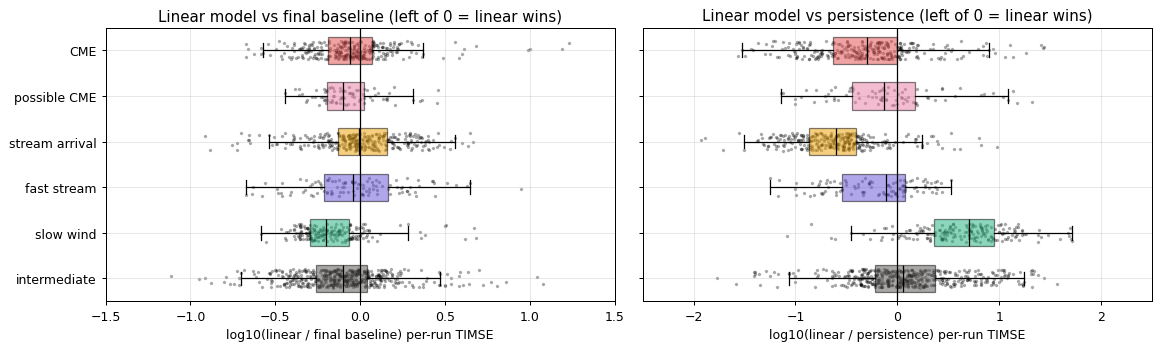

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = ev.REGIMES
for ax, (r, label) in zip(axes, [(vs_base, "final baseline"), (vs_pers, "persistence")],
                          strict=True):
    data = [np.log10(r[(regime == g).to_numpy()].dropna()) for g in order]
    parts = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True,
                       widths=0.6, medianprops={"color": "k"})
    ax.set_yticks(range(1, len(order) + 1), order)
    for patch, g in zip(parts["boxes"], order, strict=True):
        patch.set(facecolor=REGIME_COLORS[g], alpha=0.5)
    rng = np.random.default_rng(0)
    for k, d in enumerate(data, 1):
        ax.scatter(d, k + rng.uniform(-0.2, 0.2, len(d)), s=3, color="k", alpha=0.25)
    ax.axvline(0, color="k", lw=1)
    ax.set(xlabel=f"log10(linear / {label}) per-run TIMSE",
           xlim=(-1.5, 1.5) if label == "final baseline" else (-2.5, 2.5),
           title=f"Linear model vs {label} (left of 0 = linear wins)")
axes[0].invert_yaxis()
fig.tight_layout()

## 3. Bias and level

The final baseline's main failure was a constant over-forecast of quiet wind: about 100 km/s too
high in slow and intermediate wind, growing with lead. Mean residual and RMSE by lead for each
regime (top: mean residual, negative = over-forecast; bottom: RMSE).

bias 6 h RMSE 6 h bias 24 h RMSE 24 h bias 72 h RMSE 72 h
CME            linear_model      -16.2     74.3     -45.1       118     -76.6       145
               final_baseline      -10       74     -42.8       122     -57.7       131
               persistence        2.19     75.5      15.3       134        45       172
possible CME   linear_model      -12.6     31.9     -50.5        75      -147       159
               final_baseline    -15.1     35.6     -62.7      84.6      -129       143
               persistence       -6.29     35.4     -23.5        83     -63.7       116
stream arrival linear_model      -8.44     40.1     -32.3      90.3     -6.89      83.9
               final_baseline    -9.44     46.1     -49.1       103     -14.3      80.7
               persistence        9.81       46      46.3       107       144       172
fast stream    linear_model       2.28     47.8      -1.2      77.2      -163       181
               final_baseline     7.82     49.3      13.4      77.6      -133       158
               persistence        9.77     52.5      20.6       101     -97.7       152
slow wind      linear_model        -17     24.7     -73.7      82.5      -154       163
               final_baseline    -24.6     31.7     -97.8       108      -166       175
               persistence        -8.6     21.1     -24.3        44     -34.1      70.3
intermediate   linear_model      -12.5     30.5     -60.1      76.6      -162       178
               final_baseline    -17.5     35.1     -74.8      90.1      -159       174
               persistence       -6.18       32     -30.9        68     -73.4       126

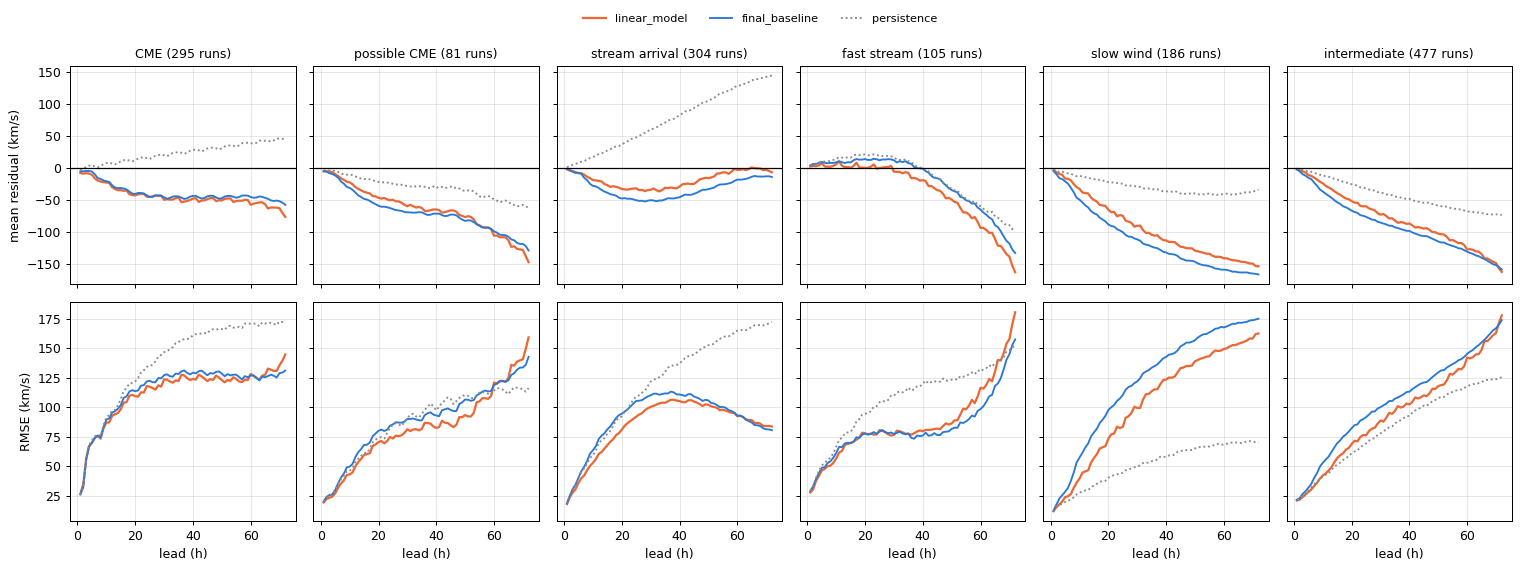

In [7]:
fig, axes = plt.subplots(2, len(ev.REGIMES), figsize=(17, 6), sharex=True, sharey="row")
bias_rows = {}
for col, g in enumerate(ev.REGIMES):
    sel = (regime == g).to_numpy()
    for m in MODELS:
        r = residuals[m][sel]
        axes[0, col].plot(lead, np.nanmean(r, axis=0), **STYLE[m])
        axes[1, col].plot(lead, np.sqrt(np.nanmean(r**2, axis=0)), **STYLE[m])
        for k in (6, 24, 72):
            bias_rows[(g, m)] = bias_rows.get((g, m), {}) | {
                f"bias {k} h": np.nanmean(r[:, k - 1]),
                f"RMSE {k} h": np.sqrt(np.nanmean(r[:, k - 1] ** 2)),
            }
    axes[0, col].axhline(0, color="k", lw=1)
    axes[0, col].set_title(f"{g} ({sel.sum()} runs)", fontsize=10)
    axes[1, col].set_xlabel("lead (h)")
axes[0, 0].set_ylabel("mean residual (km/s)")
axes[1, 0].set_ylabel("RMSE (km/s)")
fig.tight_layout()
model_legend(fig)
fmt(pd.DataFrame(bias_rows).T)

**Over-prediction in quiet wind, and the forecast floor.** For the no-CME regimes: the share of
each model's TIMSE that comes from over-prediction, and the median of (mean forecast − mean
observed) per run. Then the distribution of all forecasts at 24 h and 72 h lead against the
observed speeds (black): the final baseline almost never forecast below 450 km/s at 72 h.

share of TIMSE from over-prediction median (mean forecast - mean observed), km/s runs over-predicted on average
stream arrival linear_model                                 0.153                                         29.1                          0.668
               final_baseline                               0.273                                         39.5                          0.727
fast stream    linear_model                                  0.39                                         30.1                          0.781
               final_baseline                               0.246                                         21.5                          0.705
slow wind      linear_model                                 0.997                                         92.5                              1
               final_baseline                               0.998                                          104                              1
intermediate   linear_model                                 0.904                                         79.8                          0.981
               final_baseline                               0.918                                         86.7                          0.981

p1  p10 median  p90
24 h linear_model    371  423    501  630
     final_baseline  388  440    524  617
     observed        281  349    448  623
72 h linear_model    433  491    569  677
     final_baseline  447  502    567  655
     observed        281  349    448  623

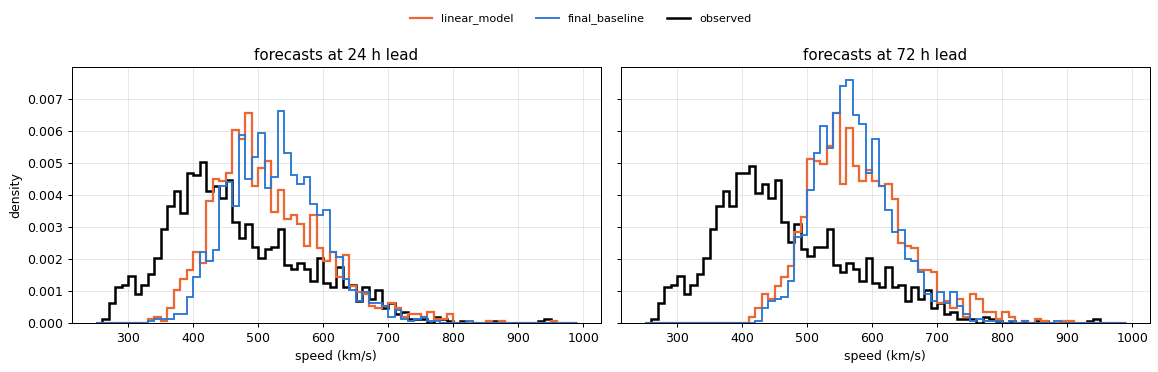

In [8]:
q = run_timse_weights(actual)
rows = {}
for g in ev.NO_CME:
    sel = (regime == g).to_numpy()
    for m in MODELS[:2]:
        e = residuals[m][sel]
        contrib = np.where(np.isfinite(e), q[sel] * e**2, 0.0)
        offset = np.nanmean(forecasts[m][sel], axis=1) - np.nanmean(actual[sel], axis=1)
        rows[(g, m)] = {
            "share of TIMSE from over-prediction": np.where(e < 0, contrib, 0).sum()
            / contrib.sum(),
            "median (mean forecast - mean observed), km/s": np.median(offset),
            "runs over-predicted on average": (offset > 0).mean(),
        }
display(fmt(pd.DataFrame(rows).T))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
bins = np.arange(250, 1000, 10)
quant = {}
for ax, k in zip(axes, (24, 72), strict=True):
    obs = actual[:, k - 1][np.isfinite(actual[:, k - 1])]
    ax.hist(obs, bins=bins, histtype="step", color="k", lw=2, density=True)
    for m in MODELS[:2]:
        ax.hist(forecasts[m][:, k - 1], bins=bins, histtype="step", density=True, **STYLE[m])
        quant[(f"{k} h", m)] = np.quantile(forecasts[m][:, k - 1], [0.01, 0.1, 0.5, 0.9])
    quant[(f"{k} h", "observed")] = np.quantile(obs, [0.01, 0.1, 0.5, 0.9])
    ax.set(title=f"forecasts at {k} h lead", xlabel="speed (km/s)")
axes[0].set_ylabel("density")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")], models=MODELS[:2])
fmt(pd.DataFrame(quant, index=["p1", "p10", "median", "p90"]).T)

## 4. Stream arrivals

The final baseline caught stream arrivals by already forecasting high, not by timing them. The
coronal-hole regressor is the one input that could give timing. A superposed-epoch view of the
non-CME stream arrivals: forecasts valid at each hour around the arrival (hour 0), made about 1, 2
or 3 days earlier, as the median over arrivals; black is the median observed speed.

The table gives the share of the observed rise each model reproduces: the mean over +12…+36 h
minus the mean over −36…−12 h, forecast over observed, median over arrivals.

29 non-CME stream arrivals


,linear_model: share of rise,final_baseline: share of rise,persistence: share of rise
~1 day ahead (19-30 h),0.414,0.27,0.42
~2 days ahead (43-54 h),0.101,0.0355,-0.156
~3 days ahead (61-72 h),0.0649,0.0236,-0.251


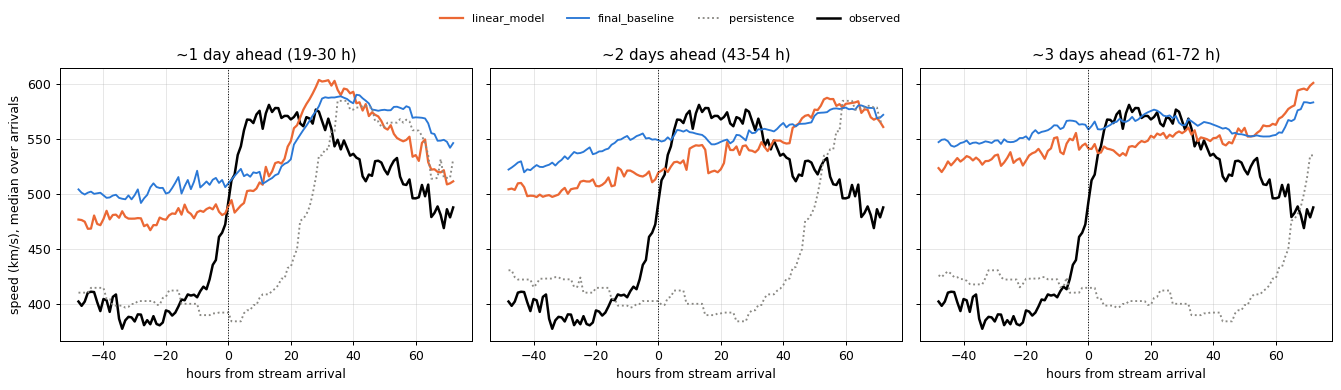

In [9]:
eval_arrivals = arrivals[(arrivals >= TRAIN_END + pd.Timedelta(days=3)) & (arrivals < EVAL_END)]
valid = t0s.values[:, None] + lead[None, :] * np.timedelta64(1, "h")
lead_grid = np.broadcast_to(lead, valid.shape)
groups = {"~1 day ahead (19-30 h)": (19, 30), "~2 days ahead (43-54 h)": (43, 54),
          "~3 days ahead (61-72 h)": (61, 72)}
rel_hours = np.arange(-48, 73)
epoch, capture = {}, {}
for gname, (lo, hi) in groups.items():
    stacks = {m: [] for m in MODELS}
    caps = {m: [] for m in MODELS}
    obs_stack = []
    for a in eval_arrivals:
        rel = (valid - a.tz_convert(None).to_datetime64()) / np.timedelta64(1, "h")
        sel = (rel >= -48) & (rel <= 72) & (lead_grid >= lo) & (lead_grid <= hi)
        obs = series.reindex(a + pd.to_timedelta(rel_hours, unit="h")).to_numpy()
        obs_stack.append(obs)
        rise_obs = np.nanmean(obs[(rel_hours >= 12) & (rel_hours <= 36)]) - np.nanmean(
            obs[(rel_hours >= -36) & (rel_hours <= -12)])
        for m in MODELS:
            df = pd.DataFrame({"rel": rel[sel].round().astype(int), "f": forecasts[m][sel]})
            curve = df.groupby("rel")["f"].mean().reindex(rel_hours)
            stacks[m].append(curve.to_numpy())
            after = curve[(curve.index >= 12) & (curve.index <= 36)].mean()
            before = curve[(curve.index >= -36) & (curve.index <= -12)].mean()
            caps[m].append((after - before) / rise_obs)
    epoch[gname] = ({m: np.nanmedian(np.array(stacks[m]), axis=0) for m in MODELS},
                    np.nanmedian(np.array(obs_stack), axis=0))
    capture[gname] = {m: np.nanmedian(caps[m]) for m in MODELS}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (gname, (curves, obs)) in zip(axes, epoch.items(), strict=True):
    ax.plot(rel_hours, obs, color="k", lw=2)
    for m in MODELS:
        ax.plot(rel_hours, curves[m], **STYLE[m])
    ax.axvline(0, color="k", lw=0.8, ls=":")
    ax.set(title=gname, xlabel="hours from stream arrival")
axes[0].set_ylabel("speed (km/s), median over arrivals")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")])
print(f"{len(eval_arrivals)} non-CME stream arrivals")
fmt(pd.DataFrame(capture).T.rename(columns=lambda m: f"{m}: share of rise"))

## 5. The regressors

### 5.1 Coefficients by lead

With no Box-Cox transform and the target relative to persistence, every term is in km/s: the
model forecasts `last + a_k + Σ b_kj·(speed term − mean) + Σ c_ki·z_i` plus a small smearing
constant. Left: the speed-term coefficients (km/s per km/s). Right: the regressor coefficients,
in km/s per standard deviation of the regressor (`z_i` is standardised on the training years).
The coefficients of the submodel (no coronal-hole regressor) are dashed.

,1,6,24,48,72
last speed,-0.0211,-0.106,-0.46,-0.628,-0.462
recurrence 27 d,0.0127,0.0427,0.206,0.234,0.239
recurrence 13.5 d,-0.00143,-0.00615,0.00348,0.0193,0.0683
bt_mean_1h,3.26,11.3,13.2,4.09,3.43
ch_cm_at_24h,-0.185,2.95,18.3,28,16.5
xray_peak_max_72h,0.293,1.83,10.2,18.4,15.8
density_mean_24h,0.768,4.67,9.36,8.16,11.5


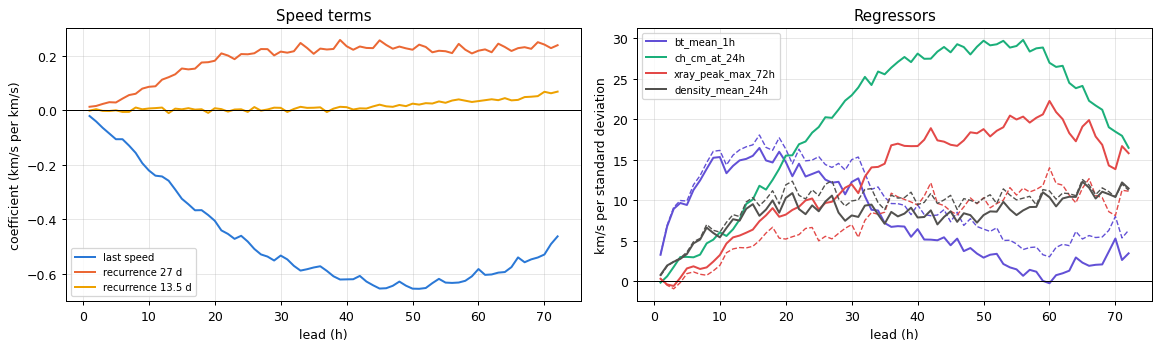

In [10]:
cfg = model.config
speed_names = ["last speed"] + [f"recurrence {d:g} d" for d in cfg.lags_days]
coef = pd.DataFrame(model.coef[:, 1:], index=lead, columns=speed_names + FEATURES)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in zip(speed_names, ["#2a78d6", "#eb6834", "#eda100"], strict=True):
    axes[0].plot(lead, coef[name], color=color, lw=1.6, label=name)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(xlabel="lead (h)", ylabel="coefficient (km/s per km/s)", title="Speed terms")
axes[0].legend(fontsize=8)
palette = ["#6250d6", "#1baf7a", "#e34948", "#52514e", "#e87ba4", "#eda100"]
feat_colors = dict(zip(FEATURES, palette, strict=False))
sub_model = model.fallback
sub_cols = 1 + sub_model.config.n_speed
for name in FEATURES:
    axes[1].plot(lead, coef[name], color=feat_colors[name], lw=1.6, label=name)
    if name in sub_model.config.features:
        j = sub_cols + sub_model.config.features.index(name)
        axes[1].plot(lead, sub_model.coef[:, j], color=feat_colors[name], lw=1.1, ls="--")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="lead (h)", ylabel="km/s per standard deviation", title="Regressors")
axes[1].legend(fontsize=8)
fig.tight_layout()
fmt(coef.loc[[1, 6, 24, 48, 72]].T)

### 5.2 Contributions by regime

Each regressor's contribution to a forecast is `c_ki · z_i` in km/s. The table gives its mean
contribution at 24 h and 72 h lead by regime, and the spread (standard deviation over runs). Only
runs forecast by the main model are included (not the submodel runs without a coronal-hole image).
If a regressor separates the regimes, its contribution should be negative in slow wind (pulling
the forecast down) and positive before stream arrivals.

In [11]:
main_runs = ~submodel.to_numpy()
z = (model.impute(x) - model.x_mean) / model.x_std
n_lead_cols = 1 + cfg.n_speed
contrib = {name: z[:, [j]] * model.coef[None, :, n_lead_cols + j]
           for j, name in enumerate(FEATURES)}
contrib["all regressors"] = sum(contrib.values())
rows = {}
for name, c in contrib.items():
    for k in (24, 72):
        row = {g: c[(regime == g).to_numpy() & main_runs, k - 1].mean() for g in ev.REGIMES}
        row["std over runs"] = c[main_runs, k - 1].std()
        rows[(name, f"{k} h")] = row
fmt(pd.DataFrame(rows).T)

CME possible CME stream arrival fast stream slow wind intermediate std over runs
bt_mean_1h        24 h   11.2         3.98           4.27        10.5     -3.18         1.07          16.2
                  72 h   2.92         1.03           1.11        2.72    -0.825        0.277          4.21
ch_cm_at_24h      24 h   9.07       -0.787           5.37        32.4     -4.93         1.61          22.8
                  72 h   8.14       -0.707           4.82        29.1     -4.43         1.45          20.5
xray_peak_max_72h 24 h   9.52         9.59           7.27        7.08      5.55         6.85          5.63
                  72 h   14.7         14.8           11.2          11      8.59         10.6           8.7
density_mean_24h  24 h  -1.91        -6.41          -4.06       -1.58      -5.4        -4.41          6.73
                  72 h  -2.34        -7.85          -4.96       -1.93      -6.6         -5.4          8.23
all regressors    24 h   27.9         6.37           12.8        48.4     -7.96         5.12          35.2
                  72 h   23.5         7.32           12.2        40.9     -3.27         6.93          27.1

### 5.3 Ablation

How much each regressor is worth on the eval year: the same fitted model, with one regressor
replaced by its training median for every run (the value an imputed run gets). The change is in
per-run mean and median TIMSE relative to the full model; positive means the regressor helps.
- **"All regressors"** replaces all four with their medians, leaving the speed terms of the main model.
- **"submodel for every run"** marks the coronal-hole image missing everywhere, so every run goes to the submodel: what the gap costs.

These are analyses of the fitted models, not refits.

In [12]:
def scores(f):
    s = run_timse(f, actual)
    return np.nanmean(s), np.nanmedian(s), timse(actual, f)


full = scores(forecasts["linear_model"])
rows = {}
for j, name in enumerate([*FEATURES, "all regressors", "submodel for every run"]):
    xa = x.copy()
    if name == "all regressors":
        xa[:] = model.medians
    elif name == "submodel for every run":
        xa[:, [FEATURES.index(f) for f in cfg.optional]] = np.nan
    else:
        xa[:, j] = model.medians[j]
    s = scores(model.forecast(values, pos, xa))
    rows[name] = {"per-run mean, worse by": s[0] / full[0] - 1,
                  "per-run median, worse by": s[1] / full[1] - 1,
                  "pooled TIMSE, worse by": s[2] / full[2] - 1,
                  "per-run mean vs baseline": s[0] / run_scores["final_baseline"].mean()}
fmt(pd.DataFrame(rows).T)

,"per-run mean, worse by","per-run median, worse by","pooled TIMSE, worse by",per-run mean vs baseline
bt_mean_1h,0.0506,0.0027,0.0509,0.95
ch_cm_at_24h,0.112,-0.124,0.261,1
xray_peak_max_72h,0.0609,-0.116,0.0633,0.959
density_mean_24h,0.00854,0.0547,-0.0145,0.912
all regressors,0.301,-0.157,0.397,1.18
submodel for every run,0.0601,0.0136,0.181,0.958


### 5.4 The coronal-hole gap

The SDO browse archive has no AIA 193 images for about 2025-09-12 → 2025-12-16, and for 9 days in
March 2026. The fallback to the 18 h or 24 h image covers only short outages, so these runs go to
the submodel without the coronal-hole regressor. In the 4-year first fit they were imputed with the
median strip instead, and the model only tied the baseline on them (median ratio 0.99, 51% of runs
won).

Top: the regressor over the year, with the submodel runs shaded. The table compares the linear
model against the final baseline on the submodel runs, and on the observed runs split by quartile
of coronal-hole area.

,runs,area range,linear mean,baseline mean,median linear / baseline,linear wins,"mean residual 72 h, linear","mean residual 72 h, baseline"
submodel,281,-,4.08e+06,4.45e+06,0.86,0.655,-104,-100
observed Q1 (small),292,0.000-0.011,9.17e+05,1.13e+06,0.586,0.822,-126,-139
observed Q2,292,0.011-0.038,1.28e+06,1.43e+06,0.731,0.75,-110,-115
observed Q3,291,0.038-0.099,1.65e+06,1.76e+06,0.919,0.619,-97.7,-93.5
observed Q4 (large),292,0.100-0.366,3.85e+06,4.26e+06,1.08,0.452,-113,-77.3


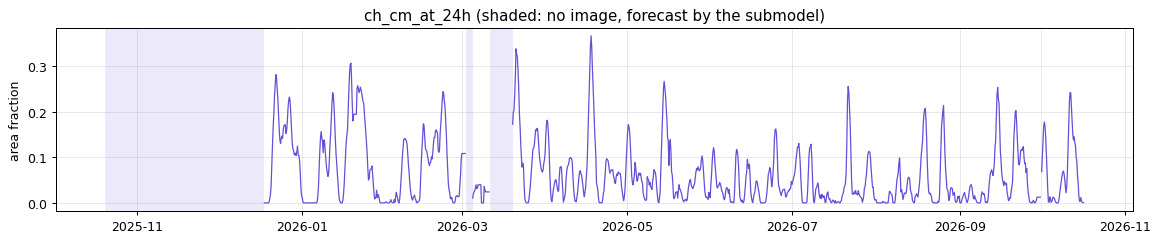

In [13]:
CH = next(f for f in FEATURES if f.startswith("ch_cm"))
ch = table[CH]
ch_missing = submodel
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.plot(ch.index, ch, color="#6250d6", lw=1)
for s, e in ev._runs(ch_missing.to_numpy()):
    ax.axvspan(t0s[s], t0s[e - 1] + pd.Timedelta(hours=6), **GAP_SPAN)
ax.set(ylabel="area fraction",
       title=f"{CH} (shaded: no image, forecast by the submodel)")
fig.tight_layout()

groups_ch = pd.Series(np.where(ch_missing, "submodel", ""), index=t0s, dtype=object)
groups_ch[~ch_missing] = pd.qcut(ch[~ch_missing], 4,
                                 labels=["observed Q1 (small)", "observed Q2", "observed Q3",
                                         "observed Q4 (large)"]).astype(str)
rows = {}
for g in ["submodel", "observed Q1 (small)", "observed Q2", "observed Q3", "observed Q4 (large)"]:
    sel = (groups_ch == g).to_numpy()
    rows[g] = {"runs": int(sel.sum()),
               "area range": f"{ch[sel].min():.3f}-{ch[sel].max():.3f}" if g != "submodel"
               else "-",
               "linear mean": run_scores.loc[sel, "linear_model"].mean(),
               "baseline mean": run_scores.loc[sel, "final_baseline"].mean(),
               "median linear / baseline": vs_base[sel].median(),
               "linear wins": (vs_base[sel] < 1).mean(),
               "mean residual 72 h, linear": np.nanmean(residuals["linear_model"][sel, 71]),
               "mean residual 72 h, baseline": np.nanmean(residuals["final_baseline"][sel, 71])}
fmt(pd.DataFrame(rows).T)

### 5.5 Despiking: the glitch before and after

The 4-year first fit's coefficients, forecasts and residuals jumped at every sixth lead (8, 14, 20, … h).
The cause was in the **training** data:
- **The glitch:** a one-hour glitch in the real-time series, 1,087 km/s at 2022-10-05 02:00 between hours of about 500 km/s.
- **Why every sixth lead:** runs start every 6 hours, so the glitch hour was the target of training runs at leads 2, 8, 14, … h.
- **Why it mattered:** TIMSE weights favour a run's fastest hours, so this single hour took up to 2% of the fitting weight at each of those leads, more than any other run-hour.

The shipped model drops such isolated one-hour glitches before fitting (`recurrence.despike`).
The table lists the hours dropped in the training years. The figure shows:
- **left:** the glitch;
- **middle:** the largest weight any single run-hour gets at each lead, on the raw targets (grey; purple where it is the glitch) and on the despiked targets (black);
- **right:** one coefficient of the shipped fit, against the same config refitted without despiking.

The refit is a training-side diagnostic, not scored here.

**What despiking doesn't remove.** A smaller six-lead pattern remains, visible in the flare
coefficient in 5.1 and in the middle panel's black line. It comes from the training design, not
from glitches:
- **The run grid:** runs start every 6 hours, so lead k only ever sees target hours at one time of day modulo 6 (lead 1 sees hours 1, 7, 13 and 19 UTC; lead 2 sees 2, 8, 14 and 20; and so on).
- **The effect:** leads in different classes are fitted on disjoint sets of hours, and any high-weight fast hour pulls one class only.
- **Fixes:** train on hourly forecast times (6× more runs, every lead sees every hour), or tie neighbouring leads together.

,speed (km/s),median of the 3 h before,median of the 3 h after
Time,,,
2020-09-28 02:00,282.0,643.0,659.0
2021-03-17 01:00,533.0,380.0,344.0
2022-01-08 01:00,634.0,299.0,297.0
2022-10-05 02:00,1087.0,497.0,503.0
2023-08-06 11:00,521.0,370.0,350.0
2023-11-24 22:00,598.0,391.0,446.0


raw targets: the glitch carries the largest single weight at 11 leads; largest share 1.0% -> 0.5% after despiking


,without despiking,shipped (despiked)
mean |second difference| over leads,,
last speed,0.0304,0.0133
recurrence 27 d,0.0365,0.0186
recurrence 13.5 d,0.0174,0.0111
bt_mean_1h,2.44,1.26
ch_cm_at_24h,2.25,1.02
xray_peak_max_72h,5.06,1.04
density_mean_24h,3.26,1.36


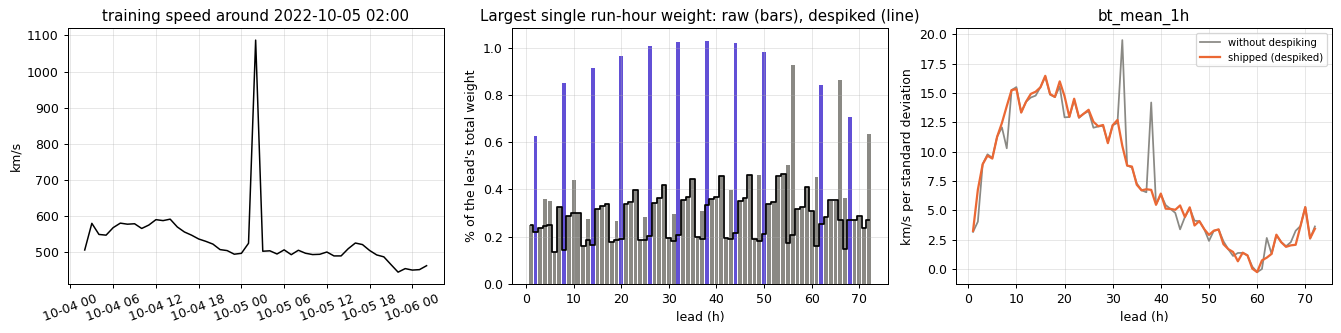

In [14]:
from dataclasses import replace

from feature_engineering.recurrence import despike
from training.datasets import load_train
from training.linear_model import training_runs

train = load_train()
tv = train.to_numpy(dtype=float)
clean = despike(tv)
dropped = np.isnan(clean) & np.isfinite(tv)
k = np.flatnonzero(dropped)
display(pd.DataFrame({"speed (km/s)": tv[k],
                      "median of the 3 h before": [np.nanmedian(tv[i - 3:i]) for i in k],
                      "median of the 3 h after": [np.nanmedian(tv[i + 1:i + 4]) for i in k]},
                     index=train.index[k].strftime("%Y-%m-%d %H:%M")).round(0))

train_t0s = training_runs(train)
tpos = train.index.get_indexer(train_t0s)


def max_share(series):
    w = model.loss_weights(targets(series, tpos))
    w = w / w.sum(axis=0)
    return w.max(axis=0), train_t0s[w.argmax(axis=0)] + pd.to_timedelta(lead, unit="h")


raw_share, raw_top = max_share(tv)
clean_share, _ = max_share(clean)
glitch = pd.Timestamp("2022-10-05T02:00Z")
is_glitch = raw_top == glitch
print(f"raw targets: the glitch carries the largest single weight at {is_glitch.sum()} leads; "
      f"largest share {raw_share.max():.1%} -> {clean_share.max():.1%} after despiking")

train_x = candidate_table(train_t0s)[FEATURES].to_numpy(dtype=float)
raw_fit = LinearModel(replace(model.config, despike=False)).fit(tv, tpos, train_x)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
w = train[glitch - pd.Timedelta(hours=24): glitch + pd.Timedelta(hours=24)]
axes[0].plot(w.index, w, color="k", lw=1.2)
axes[0].set(ylabel="km/s", title="training speed around 2022-10-05 02:00")
axes[0].tick_params(axis="x", labelrotation=20)
axes[1].bar(lead, raw_share * 100, color=np.where(is_glitch, LOSE, "#8a8984"))
axes[1].plot(lead, clean_share * 100, color="k", lw=1.4, drawstyle="steps-mid")
axes[1].set(xlabel="lead (h)", ylabel="% of the lead's total weight",
            title="Largest single run-hour weight: raw (bars), despiked (line)")
name = FEATURES[0]
j = 1 + cfg.n_speed + FEATURES.index(name)
axes[2].plot(lead, raw_fit.coef[:, j], color="#8a8984", lw=1.4, label="without despiking")
axes[2].plot(lead, model.coef[:, j], **STYLE["linear_model"], label="shipped (despiked)")
axes[2].set(xlabel="lead (h)", ylabel="km/s per standard deviation", title=name)
axes[2].legend(fontsize=8)
fig.tight_layout()


def roughness(c):
    return np.abs(np.diff(c, 2, axis=0)).mean(axis=0)


fmt(pd.DataFrame({"without despiking": roughness(raw_fit.coef[:, 1:]),
                  "shipped (despiked)": roughness(model.coef[:, 1:])},
                 index=speed_names + FEATURES).rename_axis(
                     "mean |second difference| over leads"))

## 6. Through the year

### 6.1 Month by month

Per-run mean TIMSE by month for both models, the linear model's win share, the share of runs
forecast by the submodel (no coronal-hole image), and each month's share of the year's change in the
per-run total (negative = a gain for the linear model; the column sums to −1).

,runs,linear mean,baseline mean,persistence mean,linear wins,submodel runs,CME runs,linear / baseline (means),share of total change
2025-10,48,1.26e+06,1.71e+06,3.46e+06,0.875,1,0,0.736,-0.06
2025-11,120,7.52e+06,8.16e+06,1.45e+07,0.583,1,0.4,0.922,-0.212
2025-12,124,1.66e+06,1.53e+06,4.65e+06,0.476,0.548,0.242,1.08,0.0419
2026-01,124,7.77e+06,8.6e+06,1.38e+07,0.524,0,0.25,0.903,-0.288
2026-02,112,1.16e+06,1.47e+06,3.6e+06,0.768,0,0.277,0.792,-0.0947
2026-03,124,1.38e+06,1.33e+06,3.9e+06,0.653,0.355,0.355,1.04,0.0161
2026-04,120,1.08e+06,1.35e+06,3e+06,0.65,0,0.125,0.797,-0.0912
2026-05,124,9.52e+05,1.29e+06,3.05e+06,0.694,0,0.129,0.74,-0.115
2026-06,120,1.3e+06,1.54e+06,4.19e+06,0.775,0,0.383,0.84,-0.0822
2026-07,124,8.02e+05,9.89e+05,3.79e+06,0.734,0,0.0645,0.811,-0.0642


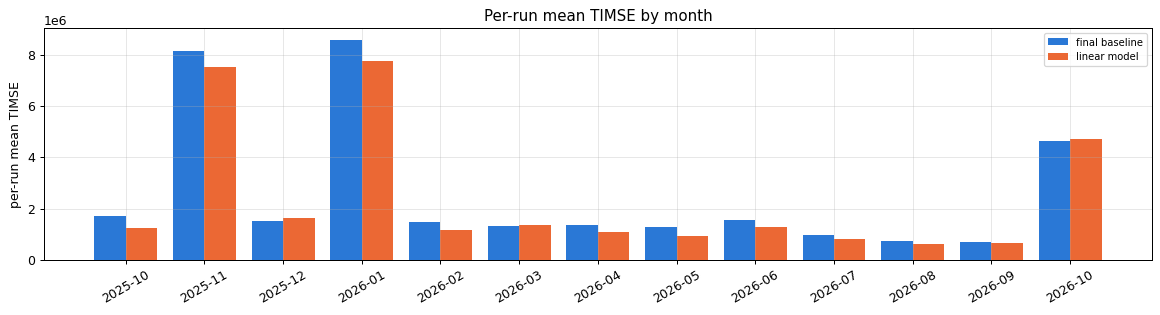

In [15]:
month = pd.Series(t0s.strftime("%Y-%m"), index=t0s)
monthly = pd.DataFrame({
    "runs": month.value_counts().sort_index(),
    "linear mean": run_scores["linear_model"].groupby(month).mean(),
    "baseline mean": run_scores["final_baseline"].groupby(month).mean(),
    "persistence mean": run_scores["persistence"].groupby(month).mean(),
    "linear wins": (vs_base < 1).groupby(month).mean(),
    "submodel runs": ch_missing.groupby(month).mean(),
    "CME runs": (regime == "CME").groupby(month).mean(),
})
monthly["linear / baseline (means)"] = monthly["linear mean"] / monthly["baseline mean"]
monthly["share of total change"] = diff.groupby(month).sum() / abs(total_change)

fig, ax = plt.subplots(figsize=(13, 3.6))
xm = np.arange(len(monthly))
ax.bar(xm - 0.2, monthly["baseline mean"], 0.4, color=STYLE["final_baseline"]["color"],
       label="final baseline")
ax.bar(xm + 0.2, monthly["linear mean"], 0.4, color=STYLE["linear_model"]["color"],
       label="linear model")
ax.set_xticks(xm, monthly.index, rotation=30)
ax.set(ylabel="per-run mean TIMSE", title="Per-run mean TIMSE by month")
ax.legend(fontsize=8)
fig.tight_layout()
fmt(monthly)

### 6.2 The year, run by run

Each pair of rows shows the observed speed (CME-affected time shaded red, possible CMEs pink,
coronal-hole regressor missing shaded purple), then the per-run ratio linear / final baseline on a
log scale at each run's `t0`: green below 1 (the linear model wins), purple above.

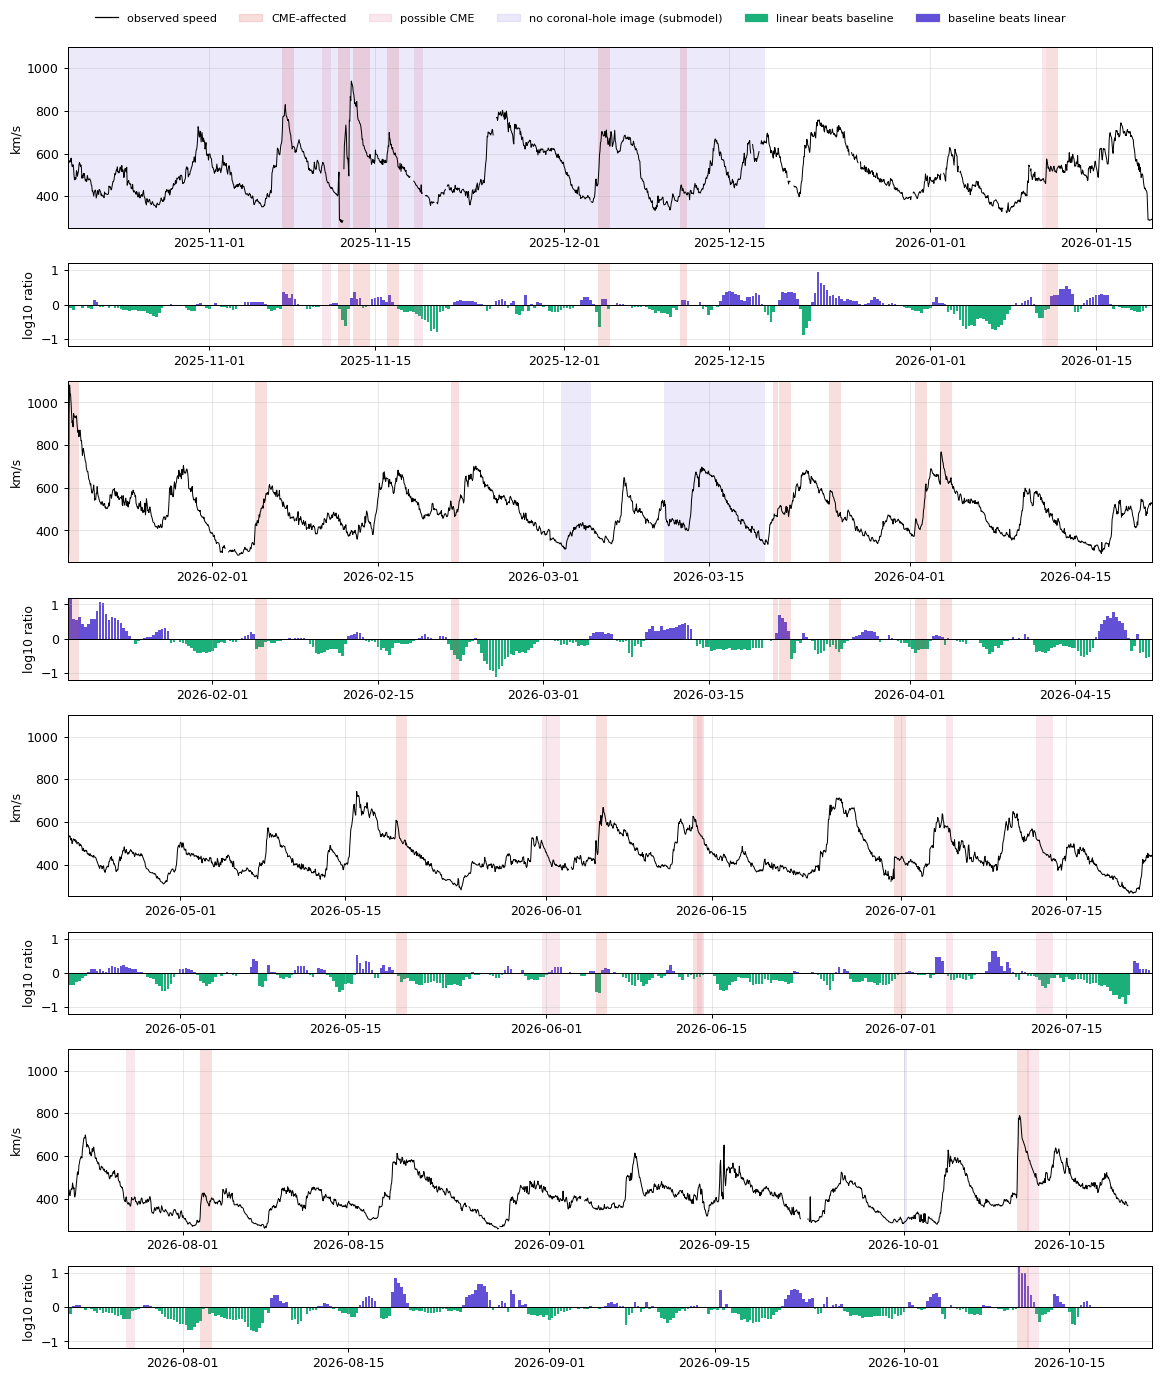

In [16]:
def shade(ax, lo, hi, gap=True):
    for mask, span in ((cme, CME_SPAN), (possible, POSSIBLE_SPAN)):
        m = mask[(mask.index >= lo) & (mask.index < hi)]
        for s, e in ev._runs(m.to_numpy()):
            ax.axvspan(m.index[s], m.index[e - 1] + pd.Timedelta(hours=1), **span)
    if gap:
        m = ch_missing[(ch_missing.index >= lo) & (ch_missing.index < hi)]
        for s, e in ev._runs(m.to_numpy()):
            ax.axvspan(m.index[s], m.index[e - 1] + pd.Timedelta(hours=6), **GAP_SPAN)


quarters = pd.date_range(TRAIN_END, EVAL_END + pd.Timedelta(days=2), periods=5)
fig, axes = plt.subplots(8, 1, figsize=(13, 15), gridspec_kw={"height_ratios": [2.2, 1] * 4})
log_ratio = np.log10(vs_base)
for k in range(4):
    lo, hi = quarters[k], quarters[k + 1]
    ax_v, ax_r = axes[2 * k], axes[2 * k + 1]
    s = series[lo:hi]
    ax_v.plot(s.index, s, color="k", lw=0.8)
    shade(ax_v, lo, hi)
    ax_v.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
    r = log_ratio[(log_ratio.index >= lo) & (log_ratio.index < hi)]
    ax_r.bar(r.index, r, width=0.22, color=np.where(r < 0, WIN, LOSE))
    ax_r.axhline(0, color="k", lw=0.8)
    shade(ax_r, lo, hi, gap=False)
    ax_r.set(ylabel="log10 ratio", xlim=(lo, hi), ylim=(-1.2, 1.2))
fig.tight_layout()
fig.legend(
    [Line2D([], [], color="k", lw=1), Patch(**{k: v for k, v in CME_SPAN.items() if k != "lw"}),
     Patch(**{k: v for k, v in POSSIBLE_SPAN.items() if k != "lw"}),
     Patch(**{k: v for k, v in GAP_SPAN.items() if k != "lw"}),
     Patch(color=WIN), Patch(color=LOSE)],
    ["observed speed", "CME-affected", "possible CME", "no coronal-hole image (submodel)",
     "linear beats baseline", "baseline beats linear"],
    loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, frameon=False, fontsize=9,
);

### 6.3 The worst runs

The ten runs with the highest linear-model TIMSE (they set the per-run mean and the p90), and
the ten where it loses most heavily to the final baseline.

In [17]:
cols = pd.DataFrame({
    "regime": regime,
    "linear": run_scores["linear_model"],
    "baseline": run_scores["final_baseline"],
    "persistence": run_scores["persistence"],
    "linear / baseline": vs_base,
    "peak observed": np.nanmax(actual, axis=1),
    "last speed": forecasts["persistence"][:, 0],
    "submodel": ch_missing,
    **{f: table[f] for f in FEATURES[:2]},
})
shown = cols.copy()
shown.index = shown.index.strftime("%Y-%m-%d %H")
print("Highest per-run TIMSE (linear model):")
display(fmt(shown.sort_values("linear", ascending=False).head(10)))
print("Largest losses to the final baseline (runs with baseline TIMSE above the median):")
big = shown[shown["baseline"] > shown["baseline"].median()]
display(fmt(big.sort_values("linear / baseline", ascending=False).head(10)))

Highest per-run TIMSE (linear model):


,regime,linear,baseline,persistence,linear / baseline,peak observed,last speed,submodel,bt_mean_1h,ch_cm_at_24h
2026-01-19 18,CME,1.82e+08,1.89e+08,2.77e+08,0.96,1.08e+03,292,False,7.06,0.179
2026-01-19 12,CME,1.44e+08,1.56e+08,2.84e+08,0.922,1.08e+03,289,False,8.74,0.213
2026-01-19 06,CME,7.41e+07,9.3e+07,1.72e+08,0.798,1.08e+03,431,False,8.33,0.268
2025-11-11 18,CME,6.37e+07,5.58e+07,9.86e+07,1.14,940,410,True,5.58,nan
2025-11-11 12,CME,5.73e+07,5.26e+07,9.12e+07,1.09,940,427,True,4.74,nan
2025-11-11 06,CME,5.33e+07,5.05e+07,8.47e+07,1.05,940,444,True,6.34,nan
2025-11-11 00,CME,4.88e+07,4.88e+07,7.57e+07,1,940,469,True,6.91,nan
2026-01-20 00,CME,4.85e+07,3.16e+06,2.29e+07,15.4,996,1.04e+03,False,61.1,0.193
2026-01-19 00,CME,4.71e+07,7.17e+07,1.28e+08,0.657,1.08e+03,501,False,7.7,0.306
2025-11-10 18,CME,4.19e+07,4.58e+07,5.09e+07,0.914,940,542,True,1.65,nan


Largest losses to the final baseline (runs with baseline TIMSE above the median):


,regime,linear,baseline,persistence,linear / baseline,peak observed,last speed,submodel,bt_mean_1h,ch_cm_at_24h
2026-01-20 00,CME,4.85e+07,3.16e+06,2.29e+07,15.4,996,1.04e+03,False,61.1,0.193
2026-04-17 18,stream arrival,4.31e+06,9.28e+05,6.15e+06,4.65,546,337,False,10.2,0.366
2026-01-20 18,fast stream,7.26e+06,1.71e+06,6.08e+06,4.23,871,839,False,20.6,0.194
2026-01-20 06,CME,1.09e+07,2.85e+06,6.78e+06,3.82,939,886,False,35.6,0.194
2026-04-17 12,stream arrival,3.32e+06,9.13e+05,7.43e+06,3.64,542,312,False,4.92,0.341
2026-01-20 12,CME,7.98e+06,2.2e+06,1.18e+07,3.63,901,928,False,14.1,0.194
2026-04-18 18,intermediate,2.91e+06,9.02e+05,1.37e+05,3.23,546,536,False,7.33,0.214
2026-09-15 12,intermediate,2.86e+06,9.03e+05,8.62e+05,3.17,651,560,False,14,0.219
2026-03-21 12,CME,2.6e+06,8.47e+05,5.25e+06,3.08,683,486,False,26,0.321
2026-03-13 00,stream arrival,4.85e+06,1.71e+06,1.64e+07,2.83,697,420,True,5.72,nan


Four examples:
- the linear model's worst run by TIMSE;
- its heaviest loss to the final baseline among stream arrivals;
- its biggest win over the final baseline in slow wind;
- its biggest win among intermediate runs.

Each panel shows the 48 h before `t0`, then the 72 h forecasts, with the observed speed in black.

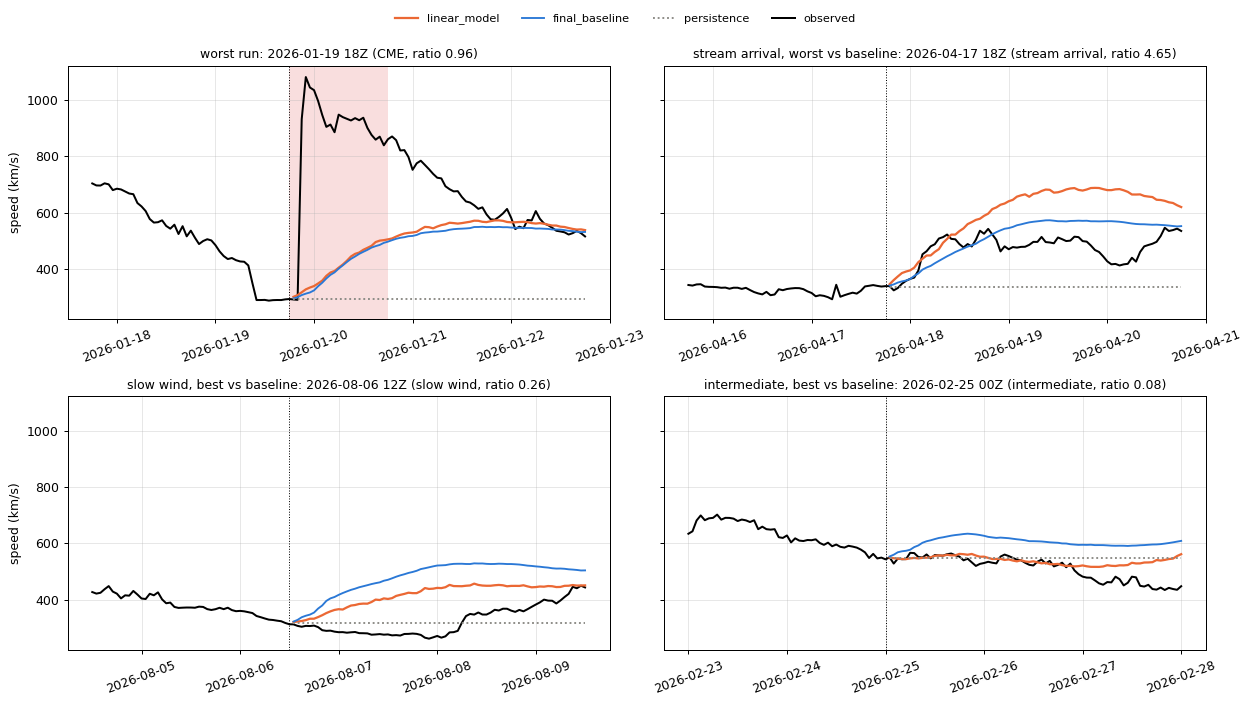

In [18]:
picks = [("worst run", cols["linear"].idxmax())]
d = cols[(regime == "stream arrival").to_numpy()]
picks.append(("stream arrival, worst vs baseline", d["linear / baseline"].idxmax()))
for g in ("slow wind", "intermediate"):
    d = cols[(regime == g).to_numpy()]
    picks.append((f"{g}, best vs baseline", d["linear / baseline"].idxmin()))

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharey=True)
for ax, (label, t0) in zip(axes.flat, picks, strict=True):
    k = t0s.get_loc(t0)
    hist = series[t0 - pd.Timedelta(hours=48): t0 + pd.Timedelta(hours=HORIZON)]
    ax.plot(hist.index, hist, color="k", lw=1.6)
    times = t0 + pd.to_timedelta(lead, unit="h")
    for m in MODELS:
        ax.plot(times, forecasts[m][k], **STYLE[m])
    ax.axvline(t0, color="k", lw=0.8, ls=":")
    shade(ax, hist.index[0], hist.index[-1], gap=False)
    ax.set_title(f"{label}: {t0:%Y-%m-%d %H}Z ({regime.iloc[k]}, "
                 f"ratio {vs_base.iloc[k]:.2f})", fontsize=10)
    ax.tick_params(axis="x", labelrotation=20)
for ax in axes[:, 0]:
    ax.set_ylabel("speed (km/s)")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.6), "observed")])

## 7. Findings

Eval year 2025-10-20 → 2026-10-20, 1,448 runs. The model is the linear model re-selected and
refitted on 9 years (2016-10 → 2025-10) with six yearly folds. The 4-year model's numbers come from
`docs/linear_model.md`.

### (i) Overall: better on typical and bad runs, slightly worse pooled

| | 9-year linear | 4-year linear | Final baseline |
|---|---|---|---|
| Pooled TIMSE | 4.82 × 10⁷ | 4.74 × 10⁷ | 5.58 × 10⁷ |
| Per-run mean | 2.34 × 10⁶ | 2.37 × 10⁶ | 2.59 × 10⁶ |
| Per-run median | 6.67 × 10⁵ | 6.76 × 10⁵ | 8.45 × 10⁵ |
| Per-run p90 | 3.43 × 10⁶ | 3.76 × 10⁶ | 3.21 × 10⁶ |
| Runs won against the baseline | 66% | 64% | |

- **Against the final baseline:** the per-run quantiles are 14–23% lower everywhere except p90, which is now only 7% higher (the 4-year model's was 17% higher).
- **The gain is spread through the year:** the model wins more runs than the baseline in 12 of 13 months, and the largest month accounts for 29% of the gain.

### (ii) By regime

| Regime | Median linear / baseline | Linear wins | Pooled linear / baseline |
|---|---|---|---|
| CME | 0.87 | 64% | 0.86 |
| possible CME | 0.79 | 73% | 1.02 |
| stream arrival | **0.98** | **51%** | 1.14 |
| fast stream | 0.91 | 55% | 0.99 |
| slow wind | 0.63 | 86% | 0.71 |
| intermediate | 0.79 | 70% | 0.82 |

- **Stream arrivals are now about level with the baseline** (median ratio 0.98, against 1.12 for the 4-year model). It reproduces 10% of the rise 2 days ahead and 6% 3 days ahead (baseline 4% and 2%).
- **The quiet-wind level at 72 h is unchanged:** a −154 km/s bias in slow wind and −162 in intermediate wind.

### (iii) The regressors

- **Effects by lead:**
  - **Bt (last hour)** acts at short leads: +11 to +13 km/s per standard deviation at 6–24 h, fading by 48 h;
  - **the coronal-hole strip (24 h)** at 24–48 h: up to +28 km/s per SD;
  - **flares (72 h)** at 48–72 h: up to +18 km/s per SD.

  Each signal covers a different part of the forecast window.
- **Ablation** (each regressor at its median):
  - the coronal-hole strip and flares save the big runs (per-run mean 11% and 6% worse without them) but cost the typical run (median 12% better without either);
  - Bt helps both the mean and pooled TIMSE by 5%;
  - density helps the median by 5%.
- **The submodel works:** runs without a coronal-hole image beat the baseline in 66% of cases (median ratio 0.86).
- **Large coronal holes still over-forecast:** the model wins only 45% of runs in the largest quarter of strip area, with a 72 h residual of −113 km/s against −77 for the baseline.

### (iv) A new failure: linear extrapolation of an extreme field

- **The run:** 2026-01-20 00Z, inside the January CME, has **15× the baseline's TIMSE** (4.9 × 10⁷), the largest single loss of the year.
- **The cause:** the last hour's Bt was **61 nT**, far beyond almost all of the training data (typical values are 4–10 nT). A linear term in Bt turns that into a large positive correction while the wind was decaying.
- **The fix:** cap each regressor at a high training quantile (e.g. the 99.5th percentile) before the linear term. Choose the cap on the training folds.

### (v) Despiking on 9 years

- **6 glitch hours** were removed from the training years, including a downward one (282 km/s inside 650 km/s wind, 2020-09-28).
- **The coefficients are about twice as smooth** with despiking.

### Caveats

- **Eval-year looks:** the eval year has been scored for the 4-year and the 9-year models; every choice was made on the training folds.
- **Regimes** come from the in-situ CME catalogue and use the observed future speed: a diagnostic, not an input.